In [3]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/

In [4]:
!kaggle datasets download -d praveengovi/emotions-dataset-for-nlp

Dataset URL: https://www.kaggle.com/datasets/praveengovi/emotions-dataset-for-nlp
License(s): CC-BY-SA-4.0
emotions-dataset-for-nlp.zip: Skipping, found more recently modified local copy (use --force to force download)


In [5]:
import zipfile
zip_ref = zipfile.ZipFile('/content/emotions-dataset-for-nlp.zip', 'r')
zip_ref.extractall('/content')
zip_ref.close()

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import nltk

import warnings
warnings.filterwarnings("ignore")


In [7]:
train_df = pd.read_csv('/content/train.txt', sep=';', header=None, names=['text', 'emotion'])

test_df = pd.read_csv('/content/test.txt', sep=';', header=None, names=['text', 'emotion'])

val_df = pd.read_csv('/content/val.txt', sep=';', header=None, names=['text', 'emotion'])

print("Training Dataset:", train_df.shape)
print("Testing Dataset:", test_df.shape)
print("Validation Dataset:", val_df.shape)


Training Dataset: (16000, 2)
Testing Dataset: (2000, 2)
Validation Dataset: (2000, 2)


In [8]:
train_df.head()

,text,emotion
0,i didnt feel humiliated,sadness
1,i can go from feeling so hopeless to so damned...,sadness
2,im grabbing a minute to post i feel greedy wrong,anger
3,i am ever feeling nostalgic about the fireplac...,love
4,i am feeling grouchy,anger


In [9]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16000 entries, 0 to 15999
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   text     16000 non-null  object
 1   emotion  16000 non-null  object
dtypes: object(2)
memory usage: 250.1+ KB


In [10]:
train_df.isnull().sum()

,0
text,0
emotion,0


In [11]:
train_df.duplicated().sum()


np.int64(1)

In [12]:
train_df['emotion'].value_counts()


,count
emotion,
joy,5362
sadness,4666
anger,2159
fear,1937
love,1304
surprise,572


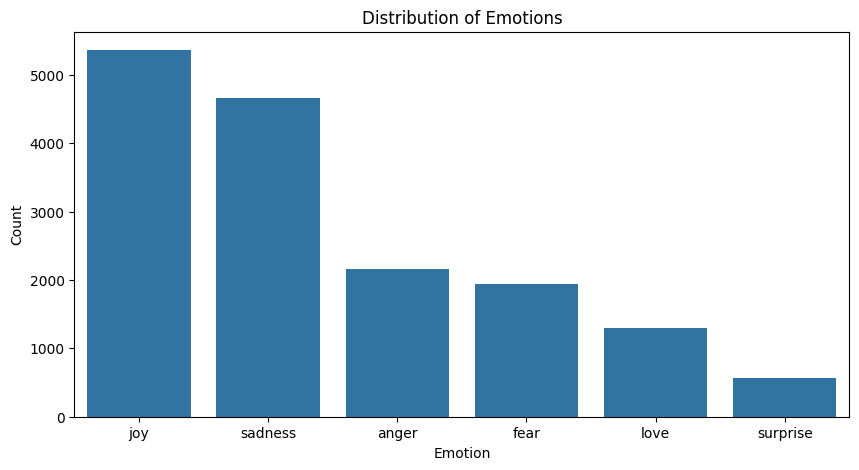

In [13]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=train_df,
    x='emotion',
    order=train_df['emotion'].value_counts().index
)

plt.title('Distribution of Emotions')
plt.xlabel('Emotion')
plt.ylabel('Count')
plt.show()


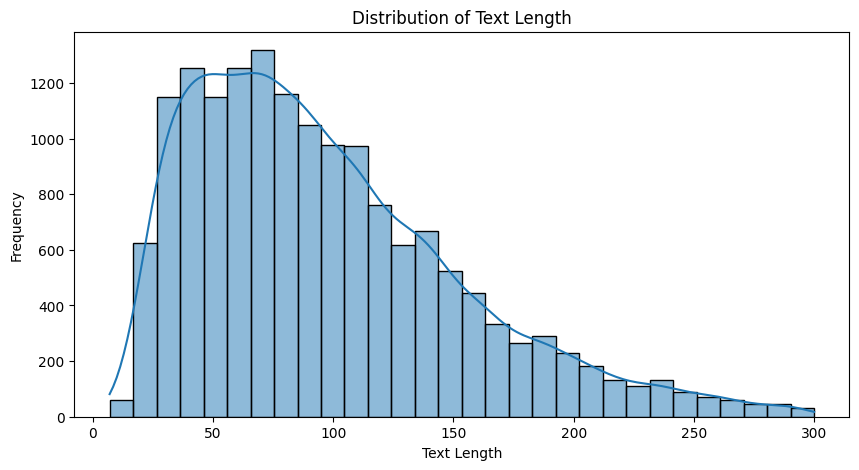

In [14]:
train_df['text_length'] = train_df['text'].str.len()

plt.figure(figsize=(10, 5))

sns.histplot(
    train_df['text_length'],
    bins=30,
    kde=True
)

plt.title('Distribution of Text Length')
plt.xlabel('Text Length')
plt.ylabel('Frequency')
plt.show()


In [15]:
train_df['text_length'].describe()


,text_length
count,16000.000000
mean,96.845812
std,55.904953
min,7.000000
25%,53.000000
50%,86.000000
75%,129.000000
max,300.000000


The dataset contains six emotion categories, with joy being the most frequent and surprise the least frequent.

The dataset is imbalanced, which may affect the prediction performance of minority classes.

There are no missing values in the training dataset.

One duplicate record was identified.

Text length is positively skewed, indicating that most sentences are relatively short, while a smaller number contain longer text.

Since this is a text classification problem, we will perform NLP preprocessing before feature extraction and model building.

In [16]:
#data cleaning
train_df.drop_duplicates(inplace=True)

print("Training Dataset Shape:", train_df.shape)
print("Duplicates:", train_df.duplicated().sum())


Training Dataset Shape: (15999, 3)
Duplicates: 0


In [17]:
import nltk

nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


True

In [18]:
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer

stop_words = set(stopwords.words('english'))

# Retain important negation words
stop_words = stop_words - {'no', 'not', 'nor'}

stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()


In [19]:
def preprocess_text(text, method='lemma'):

    # Convert to lowercase
    text = text.lower()

    # Remove special characters and numbers
    text = re.sub(r'[^a-z\s]', ' ', text)

    # Tokenization
    words = text.split()

    # Remove stopwords
    words = [word for word in words if word not in stop_words]

    # Stemming or Lemmatization
    if method == 'stem':
        words = [stemmer.stem(word) for word in words]
    elif method == 'lemma':
        words = [lemmatizer.lemmatize(word) for word in words]

    return ' '.join(words)


In [20]:
train_df['cleaned_text'] = train_df['text'].apply(preprocess_text)

val_df['cleaned_text'] = val_df['text'].apply(preprocess_text)

test_df['cleaned_text'] = test_df['text'].apply(preprocess_text)

train_df[['text', 'cleaned_text', 'emotion']].head(10)


,text,cleaned_text,emotion
0,i didnt feel humiliated,didnt feel humiliated,sadness
1,i can go from feeling so hopeless to so damned...,go feeling hopeless damned hopeful around some...,sadness
2,im grabbing a minute to post i feel greedy wrong,im grabbing minute post feel greedy wrong,anger
3,i am ever feeling nostalgic about the fireplac...,ever feeling nostalgic fireplace know still pr...,love
4,i am feeling grouchy,feeling grouchy,anger
5,ive been feeling a little burdened lately wasn...,ive feeling little burdened lately wasnt sure,sadness
6,ive been taking or milligrams or times recomme...,ive taking milligram time recommended amount i...,surprise
7,i feel as confused about life as a teenager or...,feel confused life teenager jaded year old man,fear
8,i have been with petronas for years i feel tha...,petronas year feel petronas performed well mad...,joy
9,i feel romantic too,feel romantic,love


In [21]:
for name, df in [
    ('Train', train_df),
    ('Validation', val_df),
    ('Test', test_df)
]:
    print(name, "empty cleaned texts:",
          df['cleaned_text'].str.strip().eq('').sum())


Train empty cleaned texts: 0
Validation empty cleaned texts: 0
Test empty cleaned texts: 0


Text preprocessing was performed using lowercase conversion, removal of special characters, stopword removal, and lemmatization. One duplicate record was removed from the training dataset. No empty texts were found after preprocessing. The cleaned text is ready for feature extraction and machine learning.

Feature Engineering using TF-IDF and Bag of Words

In [22]:
# Input features
X_train = train_df['cleaned_text']
X_val = val_df['cleaned_text']
X_test = test_df['cleaned_text']

# Target variables
y_train = train_df['emotion']
y_val = val_df['emotion']
y_test = test_df['emotion']

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)


X_train: (15999,)
X_val: (2000,)
X_test: (2000,)


In [23]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2)
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_val_tfidf = tfidf.transform(X_val)
X_test_tfidf = tfidf.transform(X_test)

print("Training TF-IDF Shape:", X_train_tfidf.shape)
print("Validation TF-IDF Shape:", X_val_tfidf.shape)
print("Testing TF-IDF Shape:", X_test_tfidf.shape)


Training TF-IDF Shape: (15999, 5000)
Validation TF-IDF Shape: (2000, 5000)
Testing TF-IDF Shape: (2000, 5000)


In [24]:
#apply bag of words
from sklearn.feature_extraction.text import CountVectorizer

bow = CountVectorizer(
    max_features=5000,
    ngram_range=(1, 2)
)

X_train_bow = bow.fit_transform(X_train)
X_val_bow = bow.transform(X_val)
X_test_bow = bow.transform(X_test)

print("Training BoW Shape:", X_train_bow.shape)
print("Validation BoW Shape:", X_val_bow.shape)
print("Testing BoW Shape:", X_test_bow.shape)


Training BoW Shape: (15999, 5000)
Validation BoW Shape: (2000, 5000)
Testing BoW Shape: (2000, 5000)


In [25]:
#Word2Vec Embedding
!pip install gensim -q

from gensim.models import Word2Vec


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 55.1 MB/s eta 0:00:00


In [26]:
train_tokens = X_train.apply(lambda x: x.split())
val_tokens = X_val.apply(lambda x: x.split())
test_tokens = X_test.apply(lambda x: x.split())

train_tokens.head()


,cleaned_text
0,"[didnt, feel, humiliated]"
1,"[go, feeling, hopeless, damned, hopeful, aroun..."
2,"[im, grabbing, minute, post, feel, greedy, wrong]"
3,"[ever, feeling, nostalgic, fireplace, know, st..."
4,"[feeling, grouchy]"


In [27]:
#Train the Word2Vec model
w2v_model = Word2Vec(
    sentences=train_tokens.tolist(),
    vector_size=100,
    window=5,
    min_count=1,
    workers=1,
    sg=1,
    seed=42,
    epochs=10
)

print("Vocabulary Size:", len(w2v_model.wv))


Vocabulary Size: 13487


In [28]:
#Convert sentences into vectors
def sentence_vector(tokens, model):
    vectors = [
        model.wv[word]
        for word in tokens
        if word in model.wv
    ]

    if len(vectors) == 0:
        return np.zeros(model.vector_size)

    return np.mean(vectors, axis=0)


In [29]:
#Apply Word2Vec to all datasets
X_train_w2v = np.array([
    sentence_vector(tokens, w2v_model)
    for tokens in train_tokens
])

X_val_w2v = np.array([
    sentence_vector(tokens, w2v_model)
    for tokens in val_tokens
])

X_test_w2v = np.array([
    sentence_vector(tokens, w2v_model)
    for tokens in test_tokens
])

print("Training Word2Vec Shape:", X_train_w2v.shape)
print("Validation Word2Vec Shape:", X_val_w2v.shape)
print("Testing Word2Vec Shape:", X_test_w2v.shape)


Training Word2Vec Shape: (15999, 100)
Validation Word2Vec Shape: (2000, 100)
Testing Word2Vec Shape: (2000, 100)


Word2Vec was implemented using the Skip-gram architecture with 100-dimensional embeddings. The model learned a vocabulary of 13,487 words from the training dataset. Sentence-level embeddings were generated by averaging individual word vectors. These numerical representations will be used to train and evaluate machine learning classification models.

Machine Learning Model Building

In [30]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

# Store model performance results
model_results = []

In [31]:
# Logistic Regression using TF-IDF

lr_tfidf = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_tfidf.fit(X_train_tfidf, y_train)

# Predictions
y_train_pred_lr = lr_tfidf.predict(X_train_tfidf)
y_val_pred_lr = lr_tfidf.predict(X_val_tfidf)

# Model Evaluation
print("Logistic Regression - TF-IDF")

print("Training Accuracy:",
      accuracy_score(y_train, y_train_pred_lr))

print("Validation Accuracy:",
      accuracy_score(y_val, y_val_pred_lr))

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_lr))

Logistic Regression - TF-IDF
Training Accuracy: 0.9503718982436402
Validation Accuracy: 0.8935

Classification Report:
              precision    recall  f1-score   support

       anger       0.94      0.85      0.89       275
        fear       0.89      0.80      0.84       212
         joy       0.88      0.96      0.92       704
        love       0.90      0.74      0.81       178
     sadness       0.89      0.96      0.93       550
    surprise       0.91      0.62      0.74        81

    accuracy                           0.89      2000
   macro avg       0.90      0.82      0.85      2000
weighted avg       0.89      0.89      0.89      2000



In [32]:
model_results.append({
    'Model': 'Logistic Regression',
    'Feature Extraction': 'TF-IDF',
    'Training Accuracy': accuracy_score(y_train, y_train_pred_lr),
    'Validation Accuracy': accuracy_score(y_val, y_val_pred_lr),
    'Precision': precision_score(y_val, y_val_pred_lr, average='macro', zero_division=0),
    'Recall': recall_score(y_val, y_val_pred_lr, average='macro', zero_division=0),
    'F1 Score': f1_score(y_val, y_val_pred_lr, average='macro', zero_division=0)
})

pd.DataFrame(model_results)

,Model,Feature Extraction,Training Accuracy,Validation Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,TF-IDF,0.950372,0.8935,0.901729,0.8209,0.854092


Logistic Regression achieved 95.04% training accuracy and 89.35% validation accuracy, indicating good generalization with some signs of overfitting.



Joy and sadness have strong F1-scores of 0.92 and 0.93, respectively.



Surprise has the lowest F1-score (0.74), mainly due to lower recall (0.62).



The macro F1-score of 85.41% is lower than the overall accuracy because the model performs less effectively on some minority classes.



Logistic Regression with TF-IDF provides a strong baseline for comparing other algorithms.

In [33]:
#Logistic Regression with Bag of Words
lr_bow = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_bow.fit(X_train_bow, y_train)

LogisticRegression(max_iter=1000, random_state=42)

In [34]:
y_train_pred_lr_bow = lr_bow.predict(X_train_bow)
y_val_pred_lr_bow = lr_bow.predict(X_val_bow)

In [35]:
train_acc_lr_bow = accuracy_score(y_train, y_train_pred_lr_bow)
val_acc_lr_bow = accuracy_score(y_val, y_val_pred_lr_bow)

precision_lr_bow = precision_score(
    y_val, y_val_pred_lr_bow, average='macro'
)

recall_lr_bow = recall_score(
    y_val, y_val_pred_lr_bow, average='macro'
)

f1_lr_bow = f1_score(
    y_val, y_val_pred_lr_bow, average='macro'
)

print("Training Accuracy:", train_acc_lr_bow)
print("Validation Accuracy:", val_acc_lr_bow)

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_lr_bow))

Training Accuracy: 0.9878117382336397
Validation Accuracy: 0.903

Classification Report:
              precision    recall  f1-score   support

       anger       0.92      0.89      0.90       275
        fear       0.90      0.81      0.85       212
         joy       0.91      0.93      0.92       704
        love       0.82      0.83      0.82       178
     sadness       0.93      0.95      0.94       550
    surprise       0.82      0.78      0.80        81

    accuracy                           0.90      2000
   macro avg       0.88      0.86      0.87      2000
weighted avg       0.90      0.90      0.90      2000



In [36]:
from sklearn.metrics import precision_score, recall_score


In [37]:
model_results.append({
    'Model': 'Logistic Regression',
    'Feature Extraction': 'Bag of Words',
    'Training Accuracy': train_acc_lr_bow,
    'Validation Accuracy': val_acc_lr_bow,
    'Precision': precision_lr_bow,
    'Recall': recall_lr_bow,
    'F1 Score': f1_lr_bow
})

pd.DataFrame(model_results)


,Model,Feature Extraction,Training Accuracy,Validation Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,TF-IDF,0.950372,0.8935,0.901729,0.820900,0.854092
1,Logistic Regression,Bag of Words,0.987812,0.9030,0.881258,0.864847,0.872497


Bag of Words achieved higher validation accuracy (90.30%) compared to TF-IDF (89.35%).



The macro F1-score improved from 85.41% to 87.25%, indicating better overall performance across the six emotion classes.



Bag of Words achieved better recall for the minority emotion surprise (78% compared to 62% with TF-IDF).



However, Bag of Words shows a larger training–validation accuracy gap of 8.48 percentage points, suggesting more overfitting.



Based on validation macro F1-score, Logistic Regression with Bag of Words is currently the best-performing model, although we still need to evaluate other algorithms.

In [38]:
#Logistic Regression with Word2Vec

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

scaler_w2v = StandardScaler()

X_train_w2v_scaled = scaler_w2v.fit_transform(X_train_w2v)
X_val_w2v_scaled = scaler_w2v.transform(X_val_w2v)

lr_w2v = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_w2v.fit(X_train_w2v_scaled, y_train)

LogisticRegression(max_iter=1000, random_state=42)

In [39]:
y_train_pred_lr_w2v = lr_w2v.predict(X_train_w2v_scaled)

y_val_pred_lr_w2v = lr_w2v.predict(X_val_w2v_scaled)

In [40]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

train_acc_lr_w2v = accuracy_score(
    y_train, y_train_pred_lr_w2v
)

val_acc_lr_w2v = accuracy_score(
    y_val, y_val_pred_lr_w2v
)

precision_lr_w2v = precision_score(
    y_val, y_val_pred_lr_w2v, average='macro'
)

recall_lr_w2v = recall_score(
    y_val, y_val_pred_lr_w2v, average='macro'
)

f1_lr_w2v = f1_score(
    y_val, y_val_pred_lr_w2v, average='macro'
)

print("Training Accuracy:", train_acc_lr_w2v)
print("Validation Accuracy:", val_acc_lr_w2v)

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_lr_w2v))


Training Accuracy: 0.5127195449715607
Validation Accuracy: 0.5235

Classification Report:
              precision    recall  f1-score   support

       anger       0.48      0.16      0.24       275
        fear       0.49      0.32      0.38       212
         joy       0.57      0.78      0.66       704
        love       0.46      0.12      0.19       178
     sadness       0.48      0.65      0.55       550
    surprise       0.50      0.12      0.20        81

    accuracy                           0.52      2000
   macro avg       0.50      0.36      0.37      2000
weighted avg       0.51      0.52      0.48      2000



In [41]:
model_results.append({
    'Model': 'Logistic Regression',
    'Feature Extraction': 'Word2Vec',
    'Training Accuracy': train_acc_lr_w2v,
    'Validation Accuracy': val_acc_lr_w2v,
    'Precision': precision_lr_w2v,
    'Recall': recall_lr_w2v,
    'F1 Score': f1_lr_w2v
})

pd.DataFrame(model_results)


,Model,Feature Extraction,Training Accuracy,Validation Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,TF-IDF,0.950372,0.8935,0.901729,0.820900,0.854092
1,Logistic Regression,Bag of Words,0.987812,0.9030,0.881258,0.864847,0.872497
2,Logistic Regression,Word2Vec,0.512720,0.5235,0.496326,0.357126,0.369288


In [42]:
results_df = pd.DataFrame(model_results)

lr_results = results_df[
    results_df['Model'] == 'Logistic Regression'
]

lr_results.sort_values(
    by='F1 Score',
    ascending=False
)


,Model,Feature Extraction,Training Accuracy,Validation Accuracy,Precision,Recall,F1 Score
1,Logistic Regression,Bag of Words,0.987812,0.9030,0.881258,0.864847,0.872497
0,Logistic Regression,TF-IDF,0.950372,0.8935,0.901729,0.820900,0.854092
2,Logistic Regression,Word2Vec,0.512720,0.5235,0.496326,0.357126,0.369288


Logistic Regression was evaluated using TF-IDF, Bag of Words, and Word2Vec features. Bag of Words achieved the highest validation accuracy of 90.30% and macro F1-score of 87.25%. Word2Vec performed poorly, suggesting that the averaged embeddings did not capture sufficient emotion-related information. Therefore, Bag of Words is currently the best feature extraction technique for Logistic Regression.

Decision Tree Classifier

In [43]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)


In [44]:
#Create a reusable model evaluation function
def evaluate_model(model, model_name, feature_name,
                   X_train_data, X_val_data):

    model.fit(X_train_data, y_train)

    y_train_pred = model.predict(X_train_data)
    y_val_pred = model.predict(X_val_data)

    train_acc = accuracy_score(y_train, y_train_pred)
    val_acc = accuracy_score(y_val, y_val_pred)

    precision = precision_score(
        y_val, y_val_pred, average='macro',
        zero_division=0
    )

    recall = recall_score(
        y_val, y_val_pred, average='macro',
        zero_division=0
    )

    f1 = f1_score(
        y_val, y_val_pred, average='macro',
        zero_division=0
    )

    print(f"\n{model_name} - {feature_name}")
    print("Training Accuracy:", round(train_acc, 4))
    print("Validation Accuracy:", round(val_acc, 4))
    print("Macro F1 Score:", round(f1, 4))

    print("\nClassification Report:")
    print(classification_report(y_val, y_val_pred))

    model_results.append({
        'Model': model_name,
        'Feature Extraction': feature_name,
        'Training Accuracy': train_acc,
        'Validation Accuracy': val_acc,
        'Precision': precision,
        'Recall': recall,
        'F1 Score': f1
    })

    return model


In [45]:
#Decision Tree with TF-IDF
dt_tfidf = DecisionTreeClassifier(
    max_depth=20,
    min_samples_split=5,
    random_state=42
)

dt_tfidf = evaluate_model(
    dt_tfidf,
    'Decision Tree',
    'TF-IDF',
    X_train_tfidf,
    X_val_tfidf
)


Decision Tree - TF-IDF
Training Accuracy: 0.4167
Validation Accuracy: 0.415
Macro F1 Score: 0.3098

Classification Report:
              precision    recall  f1-score   support

       anger       0.88      0.05      0.10       275
        fear       0.87      0.26      0.40       212
         joy       0.38      0.99      0.55       704
        love       0.86      0.10      0.18       178
     sadness       0.00      0.00      0.00       550
    surprise       0.78      0.53      0.63        81

    accuracy                           0.41      2000
   macro avg       0.63      0.32      0.31      2000
weighted avg       0.45      0.41      0.29      2000



In [46]:
#Decision Tree with Bag of Words
dt_bow = DecisionTreeClassifier(
    max_depth=20,
    min_samples_split=5,
    random_state=42
)

dt_bow = evaluate_model(
    dt_bow,
    'Decision Tree',
    'Bag of Words',
    X_train_bow,
    X_val_bow
)



Decision Tree - Bag of Words
Training Accuracy: 0.4153
Validation Accuracy: 0.416
Macro F1 Score: 0.3113

Classification Report:
              precision    recall  f1-score   support

       anger       0.88      0.05      0.10       275
        fear       0.78      0.29      0.42       212
         joy       0.38      0.99      0.55       704
        love       0.86      0.11      0.19       178
     sadness       0.00      0.00      0.00       550
    surprise       0.92      0.44      0.60        81

    accuracy                           0.42      2000
   macro avg       0.64      0.32      0.31      2000
weighted avg       0.45      0.42      0.29      2000



In [47]:
#Decision Tree with Word2Vec
dt_w2v = DecisionTreeClassifier(
    max_depth=20,
    min_samples_split=5,
    random_state=42
)

dt_w2v = evaluate_model(
    dt_w2v,
    'Decision Tree',
    'Word2Vec',
    X_train_w2v,
    X_val_w2v
)



Decision Tree - Word2Vec
Training Accuracy: 0.8909
Validation Accuracy: 0.3125
Macro F1 Score: 0.2212

Classification Report:
              precision    recall  f1-score   support

       anger       0.19      0.20      0.19       275
        fear       0.14      0.20      0.17       212
         joy       0.47      0.43      0.45       704
        love       0.12      0.08      0.10       178
     sadness       0.34      0.37      0.36       550
    surprise       0.08      0.05      0.06        81

    accuracy                           0.31      2000
   macro avg       0.22      0.22      0.22      2000
weighted avg       0.32      0.31      0.31      2000



In [48]:
results_df = pd.DataFrame(model_results)

results_df.sort_values(
    by='F1 Score',
    ascending=False
).reset_index(drop=True)

,Model,Feature Extraction,Training Accuracy,Validation Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,Bag of Words,0.987812,0.9030,0.881258,0.864847,0.872497
1,Logistic Regression,TF-IDF,0.950372,0.8935,0.901729,0.820900,0.854092
2,Logistic Regression,Word2Vec,0.512720,0.5235,0.496326,0.357126,0.369288
3,Decision Tree,Bag of Words,0.415276,0.4160,0.637417,0.315417,0.311285
4,Decision Tree,TF-IDF,0.416714,0.4150,0.627730,0.322775,0.309785
5,Decision Tree,Word2Vec,0.890868,0.3125,0.223953,0.222415,0.221224


Decision Tree classifiers were evaluated using TF-IDF, Bag of Words and Word2Vec. TF-IDF and Bag of Words showed underfitting, with training and validation accuracies around 41%. Word2Vec showed severe overfitting, achieving 89.09% training accuracy but only 31.25% validation accuracy. Therefore, Decision Tree did not outperform Logistic Regression. Hyperparameter tuning may help improve its performance.

Random Forest Classifier

In [49]:
from sklearn.ensemble import RandomForestClassifier

In [50]:
#Random Forest with TF-IDF
rf_tfidf = RandomForestClassifier(
    n_estimators=100,
    max_depth=None,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rf_tfidf = evaluate_model(
    rf_tfidf,
    'Random Forest',
    'TF-IDF',
    X_train_tfidf,
    X_val_tfidf
)



Random Forest - TF-IDF
Training Accuracy: 0.9249
Validation Accuracy: 0.887
Macro F1 Score: 0.8619

Classification Report:
              precision    recall  f1-score   support

       anger       0.89      0.85      0.87       275
        fear       0.81      0.86      0.84       212
         joy       0.90      0.92      0.91       704
        love       0.85      0.79      0.82       178
     sadness       0.91      0.92      0.91       550
    surprise       0.89      0.77      0.82        81

    accuracy                           0.89      2000
   macro avg       0.87      0.85      0.86      2000
weighted avg       0.89      0.89      0.89      2000



In [51]:
#Random Forest with Bag of Words
rf_bow = RandomForestClassifier(
    n_estimators=100,
    max_depth=None,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rf_bow = evaluate_model(
    rf_bow,
    'Random Forest',
    'Bag of Words',
    X_train_bow,
    X_val_bow
)



Random Forest - Bag of Words
Training Accuracy: 0.9132
Validation Accuracy: 0.8945
Macro F1 Score: 0.8682

Classification Report:
              precision    recall  f1-score   support

       anger       0.90      0.87      0.89       275
        fear       0.81      0.86      0.83       212
         joy       0.91      0.93      0.92       704
        love       0.88      0.79      0.83       178
     sadness       0.91      0.93      0.92       550
    surprise       0.86      0.78      0.82        81

    accuracy                           0.89      2000
   macro avg       0.88      0.86      0.87      2000
weighted avg       0.89      0.89      0.89      2000



In [52]:
#Random Forest with Word2Vec
rf_w2v = RandomForestClassifier(
    n_estimators=100,
    max_depth=None,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rf_w2v = evaluate_model(
    rf_w2v,
    'Random Forest',
    'Word2Vec',
    X_train_w2v,
    X_val_w2v
)



Random Forest - Word2Vec
Training Accuracy: 0.9971
Validation Accuracy: 0.4655
Macro F1 Score: 0.2291

Classification Report:
              precision    recall  f1-score   support

       anger       0.56      0.04      0.07       275
        fear       0.44      0.11      0.18       212
         joy       0.53      0.77      0.63       704
        love       0.25      0.01      0.01       178
     sadness       0.40      0.64      0.49       550
    surprise       0.00      0.00      0.00        81

    accuracy                           0.47      2000
   macro avg       0.36      0.26      0.23      2000
weighted avg       0.44      0.47      0.38      2000



In [53]:

results_df = pd.DataFrame(model_results)

results_df = results_df.sort_values(
    by='F1 Score',
    ascending=False
).reset_index(drop=True)

results_df

,Model,Feature Extraction,Training Accuracy,Validation Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,Bag of Words,0.987812,0.9030,0.881258,0.864847,0.872497
1,Random Forest,Bag of Words,0.913182,0.8945,0.878437,0.859876,0.868227
2,Random Forest,TF-IDF,0.924870,0.8870,0.874663,0.851560,0.861932
3,Logistic Regression,TF-IDF,0.950372,0.8935,0.901729,0.820900,0.854092
4,Logistic Regression,Word2Vec,0.512720,0.5235,0.496326,0.357126,0.369288
5,Decision Tree,Bag of Words,0.415276,0.4160,0.637417,0.315417,0.311285
6,Decision Tree,TF-IDF,0.416714,0.4150,0.627730,0.322775,0.309785
7,Random Forest,Word2Vec,0.997125,0.4655,0.360770,0.261452,0.229139
8,Decision Tree,Word2Vec,0.890868,0.3125,0.223953,0.222415,0.221224


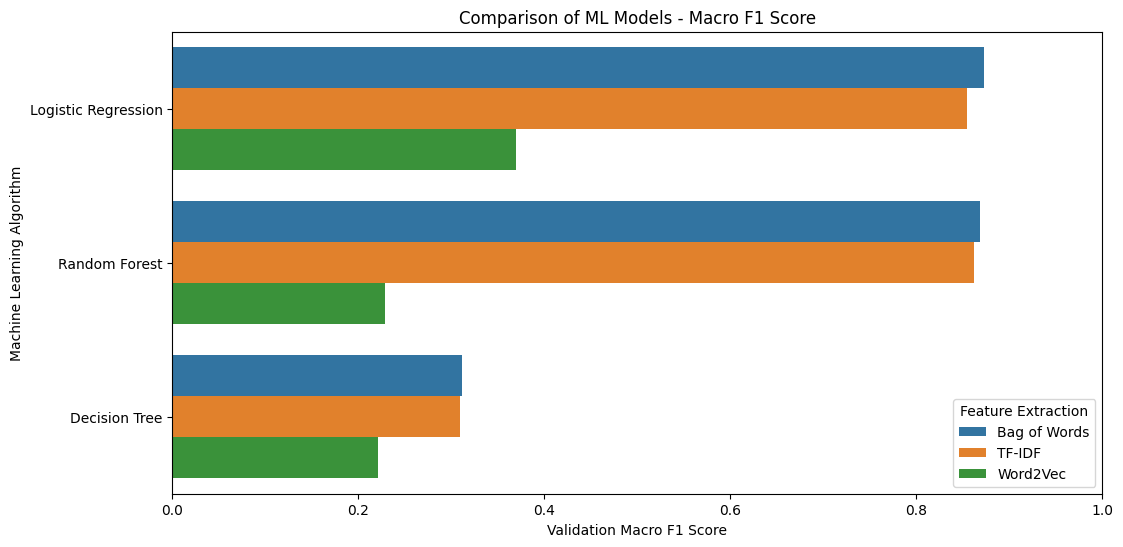

In [54]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_df,
    x='F1 Score',
    y='Model',
    hue='Feature Extraction'
)

plt.title('Comparison of ML Models - Macro F1 Score')
plt.xlabel('Validation Macro F1 Score')
plt.ylabel('Machine Learning Algorithm')
plt.xlim(0, 1)
plt.legend(title='Feature Extraction')
plt.show()


Random Forest with Bag of Words achieved the best performance among the three Random Forest models, with 89.45% validation accuracy and 86.82% macro F1-score.



Random Forest with TF-IDF also performed well, achieving 88.70% validation accuracy.



Random Forest with Word2Vec showed severe overfitting, with training accuracy of 99.71% but validation accuracy of only 46.55%.



Bag of Words and TF-IDF significantly outperformed Word2Vec for Random Forest classification.



Random Forest did not outperform Logistic Regression with Bag of Words.

Hyperparameter tuning using RandomizedSearchCV

In [55]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.linear_model import LogisticRegression
from scipy.stats import loguniform


In [58]:
#Define the Logistic Regression model and parameters
lr_model = LogisticRegression(
    max_iter=2000,
    random_state=42
)

param_dist_lr = {
    'C': loguniform(0.01, 100),
    'class_weight': [None, 'balanced'],
    'solver': ['lbfgs', 'liblinear']
}


In [59]:
random_search_lr = RandomizedSearchCV(
    estimator=lr_model,
    param_distributions=param_dist_lr,
    n_iter=12,
    cv=3,
    scoring='f1_macro',
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search_lr.fit(X_train_bow, y_train)


Fitting 3 folds for each of 12 candidates, totalling 36 fits


RandomizedSearchCV(cv=3,
                   estimator=LogisticRegression(max_iter=2000, random_state=42),
                   n_iter=12, n_jobs=-1,
                   param_distributions={'C': <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x78c0fcd9dd10>,
                                        'class_weight': [None, 'balanced'],
                                        'solver': ['lbfgs', 'liblinear']},
                   random_state=42, scoring='f1_macro', verbose=1)

In [60]:
print("Best Parameters:")
print(random_search_lr.best_params_)

print("\nBest Cross-Validation Macro F1:")
print(random_search_lr.best_score_)


Best Parameters:
{'C': np.float64(2.801635158716261), 'class_weight': 'balanced', 'solver': 'liblinear'}

Best Cross-Validation Macro F1:
0.8634763109129979


In [61]:
best_lr = random_search_lr.best_estimator_

y_train_pred_tuned_lr = best_lr.predict(X_train_bow)
y_val_pred_tuned_lr = best_lr.predict(X_val_bow)

train_acc_tuned_lr = accuracy_score(
    y_train, y_train_pred_tuned_lr
)

val_acc_tuned_lr = accuracy_score(
    y_val, y_val_pred_tuned_lr
)

precision_tuned_lr = precision_score(
    y_val, y_val_pred_tuned_lr,
    average='macro'
)

recall_tuned_lr = recall_score(
    y_val, y_val_pred_tuned_lr,
    average='macro'
)

f1_tuned_lr = f1_score(
    y_val, y_val_pred_tuned_lr,
    average='macro'
)

print("Training Accuracy:", train_acc_tuned_lr)
print("Validation Accuracy:", val_acc_tuned_lr)
print("Validation Macro F1:", f1_tuned_lr)

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_tuned_lr))


Training Accuracy: 0.988374273392087
Validation Accuracy: 0.9075
Validation Macro F1: 0.8801075684821767

Classification Report:
              precision    recall  f1-score   support

       anger       0.93      0.90      0.91       275
        fear       0.88      0.84      0.86       212
         joy       0.93      0.92      0.93       704
        love       0.80      0.88      0.84       178
     sadness       0.94      0.94      0.94       550
    surprise       0.75      0.86      0.80        81

    accuracy                           0.91      2000
   macro avg       0.87      0.89      0.88      2000
weighted avg       0.91      0.91      0.91      2000



In [62]:
model_results.append({
    'Model': 'Logistic Regression (Tuned)',
    'Feature Extraction': 'Bag of Words',
    'Training Accuracy': train_acc_tuned_lr,
    'Validation Accuracy': val_acc_tuned_lr,
    'Precision': precision_tuned_lr,
    'Recall': recall_tuned_lr,
    'F1 Score': f1_tuned_lr
})

results_df = pd.DataFrame(model_results)

results_df.sort_values(
    by='F1 Score',
    ascending=False
).reset_index(drop=True)


,Model,Feature Extraction,Training Accuracy,Validation Accuracy,Precision,Recall,F1 Score
0,Logistic Regression (Tuned),Bag of Words,0.988374,0.9075,0.871783,0.890576,0.880108
1,Logistic Regression,Bag of Words,0.987812,0.9030,0.881258,0.864847,0.872497
2,Random Forest,Bag of Words,0.913182,0.8945,0.878437,0.859876,0.868227
3,Random Forest,TF-IDF,0.924870,0.8870,0.874663,0.851560,0.861932
4,Logistic Regression,TF-IDF,0.950372,0.8935,0.901729,0.820900,0.854092
5,Logistic Regression,Word2Vec,0.512720,0.5235,0.496326,0.357126,0.369288
6,Decision Tree,Bag of Words,0.415276,0.4160,0.637417,0.315417,0.311285
7,Decision Tree,TF-IDF,0.416714,0.4150,0.627730,0.322775,0.309785
8,Random Forest,Word2Vec,0.997125,0.4655,0.360770,0.261452,0.229139
9,Decision Tree,Word2Vec,0.890868,0.3125,0.223953,0.222415,0.221224


Hyperparameter tuning was performed on Logistic Regression using RandomizedSearchCV with 3-fold cross-validation. The optimized model achieved 90.75% validation accuracy and 88.01% macro F1-score, outperforming the untuned model. The improvement indicates that hyperparameter optimization and class balancing helped improve emotion classification performance. However, the training–validation accuracy gap indicates some remaining overfitting.

In [63]:
#Hyperparameter tuning – Random Forest
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    random_state=42,
    n_jobs=-1
)

param_dist_rf = {
    'n_estimators': [100, 150],
    'max_depth': [None, 30, 50],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2']
}


In [64]:
random_search_rf = RandomizedSearchCV(
    estimator=rf_model,
    param_distributions=param_dist_rf,
    n_iter=8,
    cv=3,
    scoring='f1_macro',
    random_state=42,
    n_jobs=2,
    verbose=1
)

random_search_rf.fit(X_train_bow, y_train)

Fitting 3 folds for each of 8 candidates, totalling 24 fits


RandomizedSearchCV(cv=3,
                   estimator=RandomForestClassifier(n_jobs=-1, random_state=42),
                   n_iter=8, n_jobs=2,
                   param_distributions={'max_depth': [None, 30, 50],
                                        'max_features': ['sqrt', 'log2'],
                                        'min_samples_leaf': [1, 2, 4],
                                        'min_samples_split': [2, 5, 10],
                                        'n_estimators': [100, 150]},
                   random_state=42, scoring='f1_macro', verbose=1)

In [65]:
print("Best Parameters:")
print(random_search_rf.best_params_)

print("\nBest Cross-Validation Macro F1:")
print(random_search_rf.best_score_)

Best Parameters:
{'n_estimators': 100, 'min_samples_split': 10, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': None}

Best Cross-Validation Macro F1:
0.8462880365267272


In [66]:
best_rf = random_search_rf.best_estimator_

y_train_pred_tuned_rf = best_rf.predict(X_train_bow)
y_val_pred_tuned_rf = best_rf.predict(X_val_bow)

train_acc_tuned_rf = accuracy_score(
    y_train, y_train_pred_tuned_rf
)

val_acc_tuned_rf = accuracy_score(
    y_val, y_val_pred_tuned_rf
)

precision_tuned_rf = precision_score(
    y_val, y_val_pred_tuned_rf,
    average='macro', zero_division=0
)

recall_tuned_rf = recall_score(
    y_val, y_val_pred_tuned_rf,
    average='macro', zero_division=0
)

f1_tuned_rf = f1_score(
    y_val, y_val_pred_tuned_rf,
    average='macro', zero_division=0
)

print("Training Accuracy:", train_acc_tuned_rf)
print("Validation Accuracy:", val_acc_tuned_rf)
print("Validation Macro F1:", f1_tuned_rf)

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_tuned_rf))


Training Accuracy: 0.9901868866804175
Validation Accuracy: 0.896
Validation Macro F1: 0.8742977180814046

Classification Report:
              precision    recall  f1-score   support

       anger       0.89      0.88      0.89       275
        fear       0.82      0.88      0.85       212
         joy       0.93      0.91      0.92       704
        love       0.84      0.81      0.83       178
     sadness       0.90      0.93      0.92       550
    surprise       0.90      0.80      0.85        81

    accuracy                           0.90      2000
   macro avg       0.88      0.87      0.87      2000
weighted avg       0.90      0.90      0.90      2000



In [67]:
model_results.append({
    'Model': 'Random Forest (Tuned)',
    'Feature Extraction': 'Bag of Words',
    'Training Accuracy': train_acc_tuned_rf,
    'Validation Accuracy': val_acc_tuned_rf,
    'Precision': precision_tuned_rf,
    'Recall': recall_tuned_rf,
    'F1 Score': f1_tuned_rf
})

results_df = pd.DataFrame(model_results)

results_df.sort_values(
    by='F1 Score',
    ascending=False
).reset_index(drop=True)


,Model,Feature Extraction,Training Accuracy,Validation Accuracy,Precision,Recall,F1 Score
0,Logistic Regression (Tuned),Bag of Words,0.988374,0.9075,0.871783,0.890576,0.880108
1,Random Forest (Tuned),Bag of Words,0.990187,0.8960,0.880202,0.869915,0.874298
2,Logistic Regression,Bag of Words,0.987812,0.9030,0.881258,0.864847,0.872497
3,Random Forest,Bag of Words,0.913182,0.8945,0.878437,0.859876,0.868227
4,Random Forest,TF-IDF,0.924870,0.8870,0.874663,0.851560,0.861932
5,Logistic Regression,TF-IDF,0.950372,0.8935,0.901729,0.820900,0.854092
6,Logistic Regression,Word2Vec,0.512720,0.5235,0.496326,0.357126,0.369288
7,Decision Tree,Bag of Words,0.415276,0.4160,0.637417,0.315417,0.311285
8,Decision Tree,TF-IDF,0.416714,0.4150,0.627730,0.322775,0.309785
9,Random Forest,Word2Vec,0.997125,0.4655,0.360770,0.261452,0.229139


Hyperparameter tuning was performed on Random Forest using RandomizedSearchCV with 3-fold cross-validation. The tuned model achieved 89.60% validation accuracy and 87.43% macro F1-score. Although tuning improved the model's performance, the training–validation accuracy gap increased, indicating overfitting. Logistic Regression with Bag of Words remained the best-performing model.


In [68]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression

final_pipeline = Pipeline([
    ('vectorizer', CountVectorizer(
        max_features=5000,
        ngram_range=(1, 2)
    )),
    ('classifier', LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])


In [69]:
param_grid = {
    'classifier__C': [0.5, 1, 2, 2.8, 5],
    'classifier__class_weight': [None, 'balanced'],
    'classifier__solver': ['liblinear']
}


In [70]:
from sklearn.model_selection import GridSearchCV

grid_search = GridSearchCV(
    estimator=final_pipeline,
    param_grid=param_grid,
    cv=3,
    scoring='f1_macro',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation Macro F1:")
print(grid_search.best_score_)

Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best Parameters:
{'classifier__C': 1, 'classifier__class_weight': 'balanced', 'classifier__solver': 'liblinear'}

Best Cross-Validation Macro F1:
0.8648063182817539


In [71]:
final_model = grid_search.best_estimator_

y_train_pred_final = final_model.predict(X_train)
y_val_pred_final = final_model.predict(X_val)

print("Training Accuracy:",
      accuracy_score(y_train, y_train_pred_final))

print("Validation Accuracy:",
      accuracy_score(y_val, y_val_pred_final))

print("Validation Macro F1:",
      f1_score(y_val, y_val_pred_final, average='macro'))

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_final))


Training Accuracy: 0.9772485780361273
Validation Accuracy: 0.9075
Validation Macro F1: 0.8809258428784211

Classification Report:
              precision    recall  f1-score   support

       anger       0.91      0.89      0.90       275
        fear       0.87      0.83      0.85       212
         joy       0.95      0.92      0.93       704
        love       0.80      0.92      0.85       178
     sadness       0.94      0.93      0.93       550
    surprise       0.74      0.90      0.81        81

    accuracy                           0.91      2000
   macro avg       0.87      0.90      0.88      2000
weighted avg       0.91      0.91      0.91      2000



The final Logistic Regression model was optimized using GridSearchCV with 3-fold cross-validation and a Bag of Words vectorization pipeline. The model achieved 90.75% validation accuracy and 88.09% macro F1-score. Including vectorization within the pipeline helped prevent vocabulary leakage during cross-validation. The model performed well across all six emotion categories, although a moderate training–validation gap remained.

In [72]:
#Final model evaluation on test data
#Since Logistic Regression with Bag of Words has achieved the highest validation macro F1-score among the models evaluated, we'll select it as the final model.
# Final model selected
final_model = grid_search.best_estimator_

# Predict emotions on test data
y_test_pred = final_model.predict(X_test)

print("Test Accuracy:",
      accuracy_score(y_test, y_test_pred))

print("Test Macro F1:",
      f1_score(y_test, y_test_pred, average='macro'))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred))


Test Accuracy: 0.8995
Test Macro F1: 0.8577734160911534

Classification Report:
              precision    recall  f1-score   support

       anger       0.88      0.91      0.89       275
        fear       0.89      0.84      0.87       224
         joy       0.95      0.91      0.93       695
        love       0.72      0.87      0.79       159
     sadness       0.95      0.93      0.94       581
    surprise       0.67      0.80      0.73        66

    accuracy                           0.90      2000
   macro avg       0.84      0.88      0.86      2000
weighted avg       0.91      0.90      0.90      2000



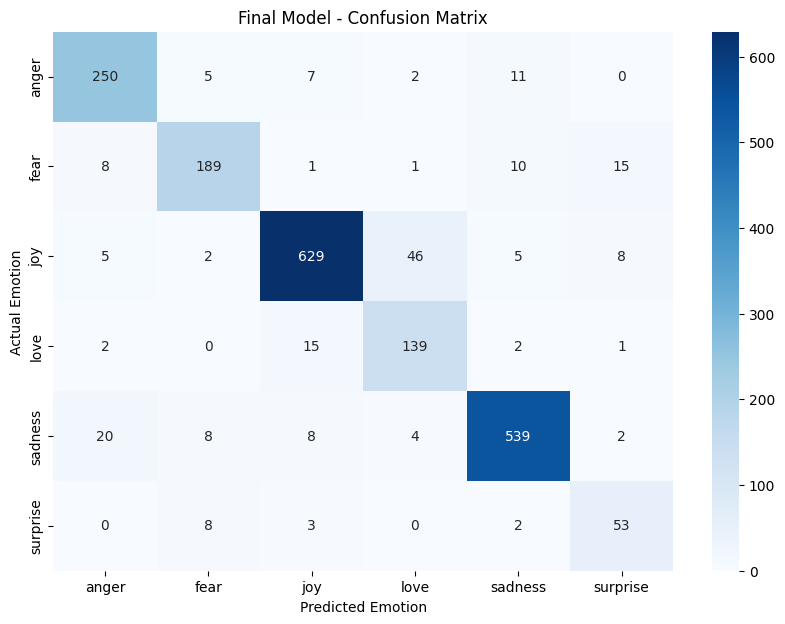

In [73]:
from sklearn.metrics import confusion_matrix

labels = sorted(y_test.unique())

cm = confusion_matrix(
    y_test,
    y_test_pred,
    labels=labels
)

plt.figure(figsize=(10, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=labels,
    yticklabels=labels
)

plt.title('Final Model - Confusion Matrix')
plt.xlabel('Predicted Emotion')
plt.ylabel('Actual Emotion')
plt.show()


In [74]:
final_performance = pd.DataFrame({
    'Metric': [
        'Training Accuracy',
        'Validation Accuracy',
        'Test Accuracy',
        'Validation Macro F1',
        'Test Macro F1'
    ],
    'Score': [
        accuracy_score(y_train, final_model.predict(X_train)),
        accuracy_score(y_val, final_model.predict(X_val)),
        accuracy_score(y_test, y_test_pred),
        f1_score(y_val, final_model.predict(X_val), average='macro'),
        f1_score(y_test, y_test_pred, average='macro')
    ]
})

final_performance


,Metric,Score
0,Training Accuracy,0.977249
1,Validation Accuracy,0.907500
2,Test Accuracy,0.899500
3,Validation Macro F1,0.880926
4,Test Macro F1,0.857773


The model achieved 89.95% test accuracy, which is close to its validation accuracy of 90.75%.



The training accuracy is higher than the test accuracy, indicating some overfitting.



The test macro F1-score of 85.77% indicates reasonably strong performance across the six emotion categories.



The model performs particularly well on joy and sadness.



Love and surprise are more challenging to classify accurately.

In [75]:
import joblib

joblib.dump(final_model, 'emotion_detection_model.pkl')

print("Model saved successfully!")


Model saved successfully!


In [76]:
from google.colab import files

files.download('emotion_detection_model.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [77]:
def predict_emotion(text):

    cleaned_text = preprocess_text(text)

    prediction = final_model.predict([cleaned_text])[0]

    return prediction


In [78]:
sample_texts = [
    "I am extremely happy today",
    "I feel very sad and lonely",
    "I am so angry about what happened",
    "I am scared of the dark",
    "I love spending time with my family",
    "I cannot believe this amazing surprise"
]

for text in sample_texts:
    emotion = predict_emotion(text)
    print(f"Text: {text}")
    print(f"Predicted Emotion: {emotion}")
    print("-" * 50)


Text: I am extremely happy today
Predicted Emotion: joy
--------------------------------------------------
Text: I feel very sad and lonely
Predicted Emotion: sadness
--------------------------------------------------
Text: I am so angry about what happened
Predicted Emotion: anger
--------------------------------------------------
Text: I am scared of the dark
Predicted Emotion: fear
--------------------------------------------------
Text: I love spending time with my family
Predicted Emotion: joy
--------------------------------------------------
Text: I cannot believe this amazing surprise
Predicted Emotion: surprise
--------------------------------------------------


In [80]:
loaded_model = joblib.load('emotion_detection_model.pkl')

sample = "I am feeling wonderful today"

cleaned_sample = preprocess_text(sample)

print("Predicted Emotion:",
      loaded_model.predict([cleaned_sample])[0])


Predicted Emotion: joy
